# Mouse brain Visium preprocess

Build one raw-count matrix per Visium section for MMF.

Each section contributes its top 1,000 spatially variable genes, scored by Moran's I. The analysis panel is the union of those two lists, restricted to genes present in the E-MTAB-11115 single-nucleus reference. Counts stay as observed UMIs: there is no molecule split and no held-out test matrix.

Spot QC is aimed at failed spots. In these sections the median mitochondrial fraction is already about 0.20, so a generic 20% mitochondrial cutoff would discard about half of each tissue.


In [1]:
from pathlib import Path
import json
import sys

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

ROOT = Path("/home/byual/MMF_codes")
sys.path.insert(0, str(ROOT))
from MMF.mmf import compute_reference_mean

RAW = Path("/import/home2/share/zw/data/mouse_brain/visium")
REF = ROOT / "data/mouse_brain/reference"
OUT = ROOT / "data/mouse_brain"
FIG = ROOT / "Mouse_brain/preprocess_figures"
FIG.mkdir(parents=True, exist_ok=True)

# Failed-spot rules. Mitochondrial median is ~0.20 in both sections.
MIN_COUNTS = 1000
MIN_GENES = 500
MAX_PCT_MT = 0.40
MIN_SPOTS_PER_GENE = 10
N_SVG = 1000
N_NEIGHBORS = 6
SECTIONS = ("Visium_1", "Visium_2")


## Load the published counts

The CSV files are the Seurat `RNA@counts` matrices exported from `brain_visium_1.rds` and `brain_visium_2.rds`, with image coordinates in the companion files.


In [2]:
def load_section(name):
    folder = RAW / name.lower()
    counts = pd.read_csv(folder / f"mouse_brain_{name.lower()}_counts.csv", index_col=0)
    coords = pd.read_csv(folder / f"mouse_brain_{name.lower()}_coordinates.csv", index_col=0)
    coords = coords.loc[counts.index, ["s_1", "s_2"]]
    matrix = counts.to_numpy(dtype=np.int32)
    return dict(genes=np.asarray(counts.columns, dtype=str),
                spots=np.asarray(counts.index, dtype=str),
                counts=matrix,
                coords=coords.to_numpy(dtype=np.float64))

loaded = {name: load_section(name) for name in SECTIONS}
for name, data in loaded.items():
    print(f"{name}: {data['counts'].shape[0]} spots x {data['counts'].shape[1]} genes")


Visium_1: 4168 spots x 32285 genes
Visium_2: 3925 spots x 32285 genes


## Spot and gene QC

A spot is removed when its total UMI is below 1,000, it detects fewer than 500 genes, or mitochondrial UMIs exceed 40% of the spot total. Genes used for spatial ranking must be detected in at least 10 retained spots. Mitochondrial genes are reported, then left out of the spatial ranking.


In [3]:
def mitochondrial(genes):
    return np.array([g.startswith("mt-") or g.startswith("MT-") for g in genes])

def qc_section(data):
    counts, genes = data["counts"], data["genes"]
    total = counts.sum(1).astype(np.float64)
    detected = (counts > 0).sum(1)
    mt = mitochondrial(genes)
    mt_frac = counts[:, mt].sum(1) / np.maximum(total, 1)
    keep = (total >= MIN_COUNTS) & (detected >= MIN_GENES) & (mt_frac <= MAX_PCT_MT)
    gene_detected = (counts[keep] > 0).sum(0)
    candidate = (gene_detected >= MIN_SPOTS_PER_GENE) & ~mt
    summary = dict(
        spots_before=int(len(keep)),
        spots_after=int(keep.sum()),
        removed_low_count=int((total < MIN_COUNTS).sum()),
        removed_few_genes=int((detected < MIN_GENES).sum()),
        removed_high_mt=int((mt_frac > MAX_PCT_MT).sum()),
        total_counts_median=float(np.median(total)),
        genes_detected_median=float(np.median(detected)),
        mitochondrial_fraction_median=float(np.median(mt_frac)),
        mitochondrial_genes=int(mt.sum()),
        genes_candidate=int(candidate.sum()),
    )
    return dict(keep=keep, total=total, detected=detected, mt_frac=mt_frac,
                candidate=candidate, summary=summary)

qc = {name: qc_section(data) for name, data in loaded.items()}
for name, result in qc.items():
    print(name)
    for key, value in result["summary"].items():
        print(f"  {key}: {value}")


Visium_1
  spots_before: 4168
  spots_after: 4097
  removed_low_count: 3
  removed_few_genes: 2
  removed_high_mt: 68
  total_counts_median: 19045.0
  genes_detected_median: 5084.5
  mitochondrial_fraction_median: 0.20504876975568964
  mitochondrial_genes: 13
  genes_candidate: 17359
Visium_2
  spots_before: 3925
  spots_after: 3892
  removed_low_count: 5
  removed_few_genes: 3
  removed_high_mt: 28
  total_counts_median: 17941.0
  genes_detected_median: 4898.0
  mitochondrial_fraction_median: 0.20133772451023665
  mitochondrial_genes: 13
  genes_candidate: 17179


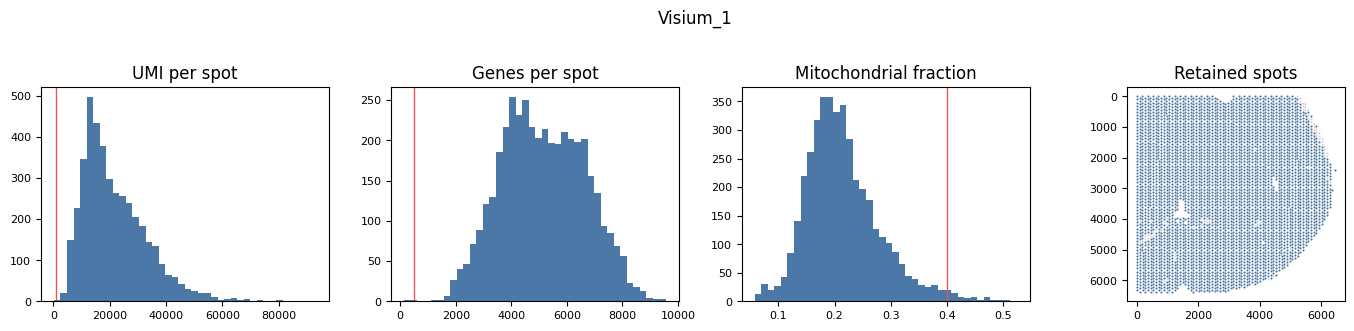

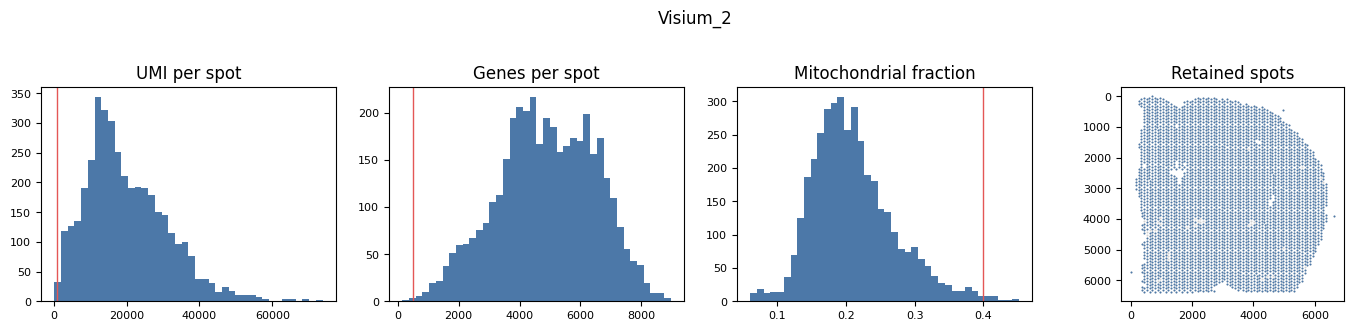

In [4]:
%matplotlib inline

def plot_qc(name, data, result):
    figure, axes = plt.subplots(1, 4, figsize=(14, 3.2))
    axes[0].hist(result["total"], bins=40, color="#4C78A8")
    axes[0].axvline(MIN_COUNTS, color="#E45756", lw=1)
    axes[0].set_title("UMI per spot")
    axes[1].hist(result["detected"], bins=40, color="#4C78A8")
    axes[1].axvline(MIN_GENES, color="#E45756", lw=1)
    axes[1].set_title("Genes per spot")
    axes[2].hist(result["mt_frac"], bins=40, color="#4C78A8")
    axes[2].axvline(MAX_PCT_MT, color="#E45756", lw=1)
    axes[2].set_title("Mitochondrial fraction")
    coords = data["coords"]
    axes[3].scatter(coords[:, 0], coords[:, 1], s=2, c="#D0D0D0", linewidths=0)
    axes[3].scatter(coords[result["keep"], 0], coords[result["keep"], 1], s=2, c="#4C78A8", linewidths=0)
    axes[3].invert_yaxis()
    axes[3].set_title("Retained spots")
    axes[3].set_aspect("equal")
    for axis in axes:
        axis.tick_params(labelsize=8)
    figure.suptitle(name, y=1.02)
    figure.tight_layout()
    figure.savefig(FIG / f"{name}_qc.png", dpi=160, bbox_inches="tight")
    plt.show()

for name in SECTIONS:
    plot_qc(name, loaded[name], qc[name])


## Spatially variable genes

For each retained spot, expression is $\log(1+10^4 \cdot y_{ig}/L_i)$, where $L_i$ is that spot's total UMI over all assayed genes. Moran's I uses the six nearest spots in the original image coordinates and row-standardized weights. Each section contributes the 1,000 genes with the largest Moran's I.


In [5]:
def moran_i(coords, expression):
    neighbors = NearestNeighbors(n_neighbors=N_NEIGHBORS + 1).fit(coords)
    index = neighbors.kneighbors(return_distance=False)[:, 1:]
    n = coords.shape[0]
    rows = np.repeat(np.arange(n), N_NEIGHBORS)
    weights = sparse.csr_matrix((np.ones(rows.size, dtype=np.float32), (rows, index.ravel())), shape=(n, n))
    scale = np.asarray(weights.sum(1)).ravel()
    weights = sparse.diags(1.0 / scale) @ weights
    centered = expression - expression.mean(0, keepdims=True)
    numerator = np.sum(centered * (weights @ centered), axis=0)
    denominator = np.sum(centered * centered, axis=0)
    score = np.full(expression.shape[1], -np.inf, dtype=np.float64)
    positive = denominator > 0
    score[positive] = numerator[positive] / denominator[positive]
    return score

svg = {}
for name in SECTIONS:
    data, result = loaded[name], qc[name]
    counts = data["counts"][result["keep"]]
    library = counts.sum(1).astype(np.float32)
    chosen = np.flatnonzero(result["candidate"])
    expression = np.log1p(counts[:, chosen].astype(np.float32) * (1e4 / library)[:, None])
    score = moran_i(data["coords"][result["keep"]], expression)
    order = np.argsort(-score, kind="stable")[:N_SVG]
    genes = data["genes"][chosen][order]
    values = score[order]
    if not np.isfinite(values).all() or (values <= 0).any():
        raise RuntimeError(f"{name} did not yield {N_SVG} genes with positive Moran's I")
    svg[name] = pd.DataFrame({"section": name, "gene": genes, "moran_i": values,
                              "rank": np.arange(1, N_SVG + 1)})
    print(name, "top gene", genes[0], f"I={values[0]:.3f}", "rank 1000", genes[-1], f"I={values[-1]:.3f}")


Visium_1 top gene Pmch I=0.884 rank 1000 Drd2 I=0.270


Visium_2 top gene Nrgn I=0.876 rank 1000 Anln I=0.247


## Panel: union, then the single-nucleus gene universe

A gene stays in the panel only when at least one section ranks it in its top 1,000 and the single-nucleus reference contains that symbol. Duplicate reference symbols are summed before the reference mean is calculated.


In [6]:
def broad_type(name):
    for prefix, major in [("Astro_", "Astrocyte"), ("Oligo_", "Oligodendrocyte"),
                          ("OPC_", "OPC"), ("Inh_", "Inhibitory"), ("Nb_", "Neuroblast"),
                          ("Ext_Hpc_", "HippocampalExc"), ("Ext_Thal_", "ThalamicExc"),
                          ("Ext_Amy_", "AmygdalarExc"), ("Ext_L", "CorticalExc")]:
        if name.startswith(prefix):
            return major
    if name == "Micro":
        return "Microglia"
    if name == "Endo":
        return "Endothelial"
    if name.startswith("Ext_"):
        return "OtherExc"
    if name.startswith(("Unk_", "LowQ_")):
        return "UnknownLowQ"
    raise ValueError(name)

reference = ad.read_h5ad(REF / "all_cells_20200625.h5ad")
symbols = reference.var["SYMBOL"].astype(str).to_numpy()
annotation = pd.read_csv(REF / "snRNA_annotation_astro_subtypes_refined59_20200823.csv", index_col=0)
fine = annotation["annotation_1"].reindex(reference.obs_names)
labelled = fine.notna().to_numpy()
reference_symbols = set(symbols)

union = sorted(set(svg["Visium_1"]["gene"]) | set(svg["Visium_2"]["gene"]))
panel = np.array([gene for gene in union if gene in reference_symbols], dtype=str)
missing = sorted(set(union) - set(panel.tolist()))
print(f"union {len(union)}; in reference {len(panel)}; absent from reference {len(missing)}")
if missing:
    print("absent:", ", ".join(missing[:30]))

both = set(svg["Visium_1"]["gene"]) & set(svg["Visium_2"]["gene"])
print(f"nominated by both sections: {len(both & reference_symbols)}")


union 1089; in reference 1067; absent from reference 22
absent: 1700094D03Rik, 2010204K13Rik, 2810468N07Rik, 9130024F11Rik, Atp5md, Ccn2, Ccn3, Ecrg4, Gas5, Inka2, Minar2, Mrtfb, Oip5os1, Pakap.1, Plaat3, Rnf227, Shisal1, Sox2ot, Tafa1, Tafa2, Tafa4, Vxn
nominated by both sections: 892


In [7]:
visium_genes = set(loaded["Visium_1"]["genes"]).intersection(loaded["Visium_2"]["genes"])
in_universe = np.isin(symbols, list(visium_genes))
universe = np.array(sorted(set(symbols[in_universe])), dtype=str)
universe_index = {gene: i for i, gene in enumerate(universe)}
columns = np.flatnonzero(in_universe)
rows = np.array([universe_index[symbols[j]] for j in columns])
merger = sparse.csr_matrix((np.ones(columns.size, dtype=np.float32), (columns, rows)),
                           shape=(symbols.size, universe.size))
counts_ref = (reference[labelled].X @ merger).tocsr()
labels = np.array([broad_type(name) for name in fine[labelled].astype(str)], dtype=str)
types = np.array(sorted(set(labels.tolist())), dtype=str)
panel_index = np.array([universe_index[gene] for gene in panel])
panel_counts = counts_ref[:, panel_index].toarray()
universe_library = np.asarray(counts_ref.sum(1)).ravel()
eta0, eta_types = compute_reference_mean(panel_counts, labels, cell_types=types.tolist(),
                                         library_size=universe_library)
eta0 = eta0.astype(np.float32)
assert list(eta_types) == types.tolist()
assert np.isfinite(eta0).all() and (eta0 >= 0).all()
print("reference cells", int(labelled.sum()), "types", len(types), "universe genes", len(universe))
print(pd.Series(labels).value_counts().reindex(types).to_string())


reference cells 40532 types 13 universe genes 29814
AmygdalarExc        1316
Astrocyte           3013
CorticalExc         5698
Endothelial           22
HippocampalExc      2420
Inhibitory          8471
Microglia           1218
Neuroblast           428
OPC                 1315
Oligodendrocyte    11432
OtherExc            2007
ThalamicExc         1868
UnknownLowQ         1324


## Save both sections

`Y` is the raw UMI submatrix on the shared panel. `library_size` is the row sum of `Y`, which is the exposure used by the fitter. `eta0` is the reference mean of panel UMIs divided by the common-universe library, without renormalizing the panel. Coordinates stored for the fit are shifted and scaled separately within each section; `original_coords` keeps the image coordinates.


In [8]:
def initial_pi(counts, profiles):
    library = counts.sum(1, keepdims=True).astype(np.float64)
    projected = (counts.astype(np.float64) @ profiles.T) / library
    gram = profiles @ profiles.T
    weights = projected @ np.linalg.pinv(gram, hermitian=True)
    weights = np.maximum(weights, 1e-3)
    weights /= weights.sum(1, keepdims=True)
    return weights.astype(np.float32)

def normalized_coords(coords):
    origin = coords.min(0)
    scale = np.ptp(coords, axis=0).max()
    return ((coords - origin) / scale).astype(np.float32), origin, float(scale)

k_list = np.array([0 if name == "UnknownLowQ" else 1 for name in types], dtype=np.int64)
records = []
for name in SECTIONS:
    data, result = loaded[name], qc[name]
    keep = result["keep"]
    column = np.array([data["genes"].tolist().index(gene) for gene in panel])
    observed = data["counts"][keep][:, column]
    positive = observed.sum(1) > 0
    observed = observed[positive]
    spot_names = data["spots"][keep][positive]
    original = data["coords"][keep][positive]
    coords, origin, scale = normalized_coords(original)
    library = observed.sum(1).astype(np.float64)
    payload = dict(
        Y=observed.astype(np.float32),
        eta0=eta0,
        pi=initial_pi(observed, eta0),
        coords=coords,
        library_size=library,
        genes=panel,
        cell_types=types,
        original_indices=np.flatnonzero(keep)[positive].astype(np.int64),
        original_coords=original,
        spot_names=spot_names,
        K_list=k_list,
        total_counts=result["total"][keep][positive].astype(np.float64),
    )
    assert np.array_equal(payload["library_size"], payload["Y"].sum(1))
    assert np.all(payload["library_size"] > 0)
    assert np.max(np.abs(payload["Y"] - np.round(payload["Y"]))) == 0
    destination = OUT / f"{name}.npz"
    temporary = OUT / f".{name}.partial.npz"
    np.savez_compressed(temporary, **payload)
    temporary.replace(destination)
    records.append(dict(section=name, spots=int(observed.shape[0]), genes=int(observed.shape[1]),
                        removed_spots=int((~keep).sum()), dropped_zero_panel=int((~positive).sum()),
                        coordinate_origin=origin.tolist(), coordinate_scale=scale,
                        total_umi=int(observed.sum()), file=str(destination)))
    print(name, records[-1])

scores = pd.concat([svg[name] for name in SECTIONS], ignore_index=True)
scores["in_reference"] = scores["gene"].isin(reference_symbols)
scores["in_panel"] = scores["gene"].isin(set(panel))
scores.to_csv(OUT / "svg_selection.csv", index=False)
manifest = dict(
    count_policy="Observed UMI on the shared panel. No molecule split and no train/test partition.",
    svg="Moran I on log1p(CP10k), 6 nearest image-coordinate neighbors, row-standardized weights.",
    svg_per_section=N_SVG,
    qc=dict(min_counts=MIN_COUNTS, min_genes=MIN_GENES, max_mitochondrial_fraction=MAX_PCT_MT,
            min_spots_per_gene=MIN_SPOTS_PER_GENE, mitochondrial_genes_excluded_from_svg=True),
    sections={name: qc[name]["summary"] for name in SECTIONS},
    union_genes=len(union),
    panel_genes=int(len(panel)),
    absent_from_reference=missing,
    reference=str(REF / "all_cells_20200625.h5ad"),
    reference_cells=int(labelled.sum()),
    reference_universe_genes=int(len(universe)),
    cell_types=types.tolist(),
    eta0="Mean within broad type of panel UMI divided by the common-universe UMI. Panel is not renormalized.",
    outputs=records,
)
(OUT / "preprocess_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
print("panel genes", len(panel))


Visium_1 {'section': 'Visium_1', 'spots': 4097, 'genes': 1067, 'removed_spots': 71, 'dropped_zero_panel': 0, 'coordinate_origin': [0.0, 0.0], 'coordinate_scale': 6450.234, 'total_umi': 27049030, 'file': '/home/byual/MMF_codes/data/mouse_brain/Visium_1.npz'}


Visium_2 {'section': 'Visium_2', 'spots': 3892, 'genes': 1067, 'removed_spots': 33, 'dropped_zero_panel': 0, 'coordinate_origin': [0.0, 0.0], 'coordinate_scale': 6626.142, 'total_umi': 23589255, 'file': '/home/byual/MMF_codes/data/mouse_brain/Visium_2.npz'}
panel genes 1067
